# Course 13: Machine Learning for Agriculture and Climate
## Session 12: Responsible machine learning for farmers and the climate, and the capstone

**Goal:** estimate the energy and CO2 of training and running models from stated assumptions, turn a rain probability into Bangla advice with honest uncertainty wording, compare the value of personal and one-size advice for farmers with different costs and losses, and write a model card.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Energy and CO₂ from stated assumptions
The energy of a computation is roughly

$$E\ (\text{kWh}) = \text{power per device (kW)} \times \text{hours} \times \text{number of devices} \times \text{PUE},$$

where the **power usage effectiveness** (PUE) adds the data centre's cooling and other overheads (1.0 would mean none). The emissions are $E$ times the **carbon intensity** of the electricity grid (kg CO₂ per kWh), which differs hugely between grids. Hardware manufacturing adds more, which this simple formula leaves out.

**Every number in the table below except two is an assumption, labelled as such.** The exceptions: GraphCast was trained for about four weeks on 32 Cloud TPU v4 devices and makes a 10-day forecast in under a minute (Lam et al. 2023). The per-device power, the PUE and the grid intensities are assumptions for illustration: replace them with measured or sourced figures before quoting any result. We first **measure** one small job on this machine, the honest way to start.

measured: the model took 0.2 s of CPU time on one core
                                                 job     hours  energy (kWh)  kg CO2, low-carbon grid, 0.05  kg CO2, assumed 0.6  kg CO2, coal-heavy grid, 0.9
         the model above, laptop CPU (measured time) 6.395e-05     9.593e-07                      4.796e-08            5.756e-07                     8.633e-07
      fine-tune a leaf-disease CNN, 1 cloud GPU, 3 h         3          0.99                         0.0495                0.594                         0.891
   train a GraphCast-size model, 32 devices, 4 weeks       672         4,731                          236.5                2,839                         4,258
run one 10-day forecast a day for a year, 1 min each     6.083         1.338                        0.06692                0.803                         1.205
training the large model used 3,535 times the energy of a year of daily forecasts with it


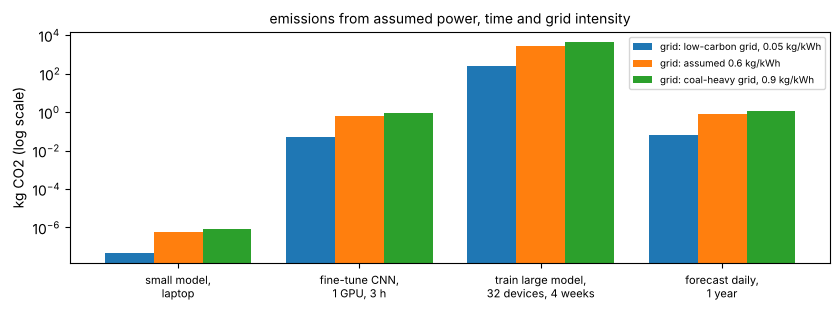

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

t_start = time.time()
np.random.seed(0)
rng = np.random.default_rng(0)

# measure: a gradient-boosting yield model like session 5's, on 20,000 synthetic rows
X = rng.normal(size=(20000, 8)); y = X[:, 0] - 0.5 * X[:, 1] ** 2 + rng.normal(0, 0.3, 20000)
with threadpool_limits(1):                                        # one thread, so CPU time is one core's time
    c0 = time.process_time()
    HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(X, y)
    cpu_seconds = time.process_time() - c0
print(f"measured: the model took {cpu_seconds:.1f} s of CPU time on one core")

ASSUMED = {"CPU core power (kW)": 0.015, "accelerator power (kW)": 0.2, "cloud GPU power (kW)": 0.3,
           "PUE, laptop": 1.0, "PUE, data centre": 1.1}
GRIDS = {"low-carbon grid, 0.05": 0.05, "assumed 0.6": 0.6, "coal-heavy grid, 0.9": 0.9}   # kg CO2 per kWh, all assumed
jobs = pd.DataFrame([
    ("the model above, laptop CPU (measured time)", ASSUMED["CPU core power (kW)"], cpu_seconds / 3600, 1, ASSUMED["PUE, laptop"]),
    ("fine-tune a leaf-disease CNN, 1 cloud GPU, 3 h", ASSUMED["cloud GPU power (kW)"], 3, 1, ASSUMED["PUE, data centre"]),
    ("train a GraphCast-size model, 32 devices, 4 weeks", ASSUMED["accelerator power (kW)"], 4 * 7 * 24, 32, ASSUMED["PUE, data centre"]),
    ("run one 10-day forecast a day for a year, 1 min each", ASSUMED["accelerator power (kW)"], 365 / 60, 1, ASSUMED["PUE, data centre"]),
], columns=["job", "kW per device", "hours", "devices", "PUE"])
jobs["energy (kWh)"] = jobs["kW per device"] * jobs["hours"] * jobs["devices"] * jobs["PUE"]
for g, intensity in GRIDS.items():
    jobs[f"kg CO2, {g}"] = jobs["energy (kWh)"] * intensity
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
print(jobs.drop(columns=["kW per device", "devices", "PUE"]).to_string(index=False, float_format=lambda v: f"{v:,.4g}"))
ratio = jobs.loc[2, "energy (kWh)"] / jobs.loc[3, "energy (kWh)"]
print(f"training the large model used {ratio:,.0f} times the energy of a year of daily forecasts with it")

fig, ax = plt.subplots(figsize=(8.5, 3.2))
w = 0.27
for i, (g, intensity) in enumerate(GRIDS.items()):
    ax.bar(np.arange(len(jobs)) + (i - 1) * w, jobs["energy (kWh)"] * intensity, w, label=f"grid: {g} kg/kWh")
ax.set_yscale("log"); ax.set_xticks(np.arange(len(jobs)))
ax.set_xticklabels(["small model,\nlaptop", "fine-tune CNN,\n1 GPU, 3 h", "train large model,\n32 devices, 4 weeks", "forecast daily,\n1 year"], fontsize=8)
ax.set_ylabel("kg CO2 (log scale)"); ax.set_title("emissions from assumed power, time and grid intensity", fontsize=10)
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### 2. From a probability to Bangla advice
A forecast of "38%" means little on its own. Advice that a farmer can use says **what to do, why, and how sure we are**. Here three common actions after the rice harvest have different costs and losses, so they have different cost/loss thresholds (session 10): act when the probability of heavy rain is above $C/L$. The thresholds are assumptions for illustration.

The message gives the chance in words, as a number, and as a **frequency** ("in the past, after a forecast like this, heavy rain came about 4 times in 10"), which a farmer can compare with experience. It must also be true: the frequency comes from the forecast's record, a reliability table like session 10's, not from the forecast's own number.

In [2]:
BN_DIGITS = str.maketrans("0123456789", "০১২৩৪৫৬৭৮৯")
bn = lambda x: str(x).translate(BN_DIGITS)

ACTIONS = [  # (cost/loss threshold, Bangla, English) - thresholds are illustrative assumptions
    (0.1, "কাটা ধান ঢেকে রাখুন বা শুকনো জায়গায় সরিয়ে নিন।", "cover the harvested paddy or move it to a dry place"),
    (0.3, "ইউরিয়া সার দেওয়া দুই দিন পিছিয়ে দিন।", "delay applying urea fertilizer by two days"),
    (0.6, "পাকা ধান আগেভাগে কাটার ব্যবস্থা করুন।", "arrange to harvest the ripe paddy early"),
]

def words(p):
    if p < 0.2: return "কম", "low"
    if p < 0.5: return "মাঝারি", "moderate"
    if p < 0.8: return "বেশি", "high"
    return "খুব বেশি", "very high"

# the forecast's record: on past days with forecasts in each 10% band, how often did heavy rain come?
p_hist = rng.beta(0.6, 3.4, 3000)
rain_hist = rng.random(3000) < np.clip(1.15 * p_hist, 0, 1)        # this forecaster is slightly too cautious (underforecasts)
band = np.minimum((p_hist * 10).astype(int), 9)
record = {b: (rain_hist[band == b].mean(), int((band == b).sum())) for b in range(10)}

def advice(p):
    b = min(int(p * 10), 9)
    freq, n = record[b]
    k = int(round(10 * freq))
    w_bn, w_en = words(p)
    if k >= 1:
        freq_bn = f"আগে এমন পূর্বাভাস দেওয়া হলে প্রতি ১০ বারের মধ্যে প্রায় {bn(k)} বার ভারী বৃষ্টি হয়েছে।"
        freq_en = f"In the past, after a forecast like this, heavy rain came about {k} times in 10"
    else:
        freq_bn = "আগে এমন পূর্বাভাস দেওয়া হলে ১০ বারের মধ্যে ১ বারেরও কম ভারী বৃষ্টি হয়েছে।"
        freq_en = "In the past, after a forecast like this, heavy rain came less than once in 10"
    lines_bn = [f"আগামী দুই দিনে ভারী বৃষ্টির সম্ভাবনা {w_bn} ({bn(round(100 * p))}%)। " + freq_bn]
    lines_en = [f"Chance of heavy rain in the next two days: {w_en} ({round(100 * p)}%). " + freq_en + f" ({n} past forecasts)."]
    todo = [(bn_text, en_text) for thr, bn_text, en_text in ACTIONS if p > thr]
    if todo:
        lines_bn += [t for t, _ in todo]; lines_en += [f"Do: {e}." for _, e in todo]
    else:
        lines_bn.append("এখনই কিছু করার দরকার নেই; কাল আবার পূর্বাভাস দেখুন।"); lines_en.append("No action needed now; check the forecast again tomorrow.")
    return "\n".join(lines_bn), "\n".join(lines_en)

for p in [0.08, 0.38, 0.72]:
    text_bn, text_en = advice(p)
    print(f"--- forecast probability {p:.2f}\n{text_bn}\n{text_en}")
print(f"\nthe record: forecasts of 30-40% averaged {p_hist[band == 3].mean():.0%}, and heavy rain came after {record[3][0]:.0%} of them; "
      f"forecasts of 70-80% averaged {p_hist[band == 7].mean():.0%}, and heavy rain came after {record[7][0]:.0%} of them")

--- forecast probability 0.08
আগামী দুই দিনে ভারী বৃষ্টির সম্ভাবনা কম (৮%)। আগে এমন পূর্বাভাস দেওয়া হলে ১০ বারের মধ্যে ১ বারেরও কম ভারী বৃষ্টি হয়েছে।
এখনই কিছু করার দরকার নেই; কাল আবার পূর্বাভাস দেখুন।
Chance of heavy rain in the next two days: low (8%). In the past, after a forecast like this, heavy rain came less than once in 10 (1551 past forecasts).
No action needed now; check the forecast again tomorrow.
--- forecast probability 0.38
আগামী দুই দিনে ভারী বৃষ্টির সম্ভাবনা মাঝারি (৩৮%)। আগে এমন পূর্বাভাস দেওয়া হলে প্রতি ১০ বারের মধ্যে প্রায় ৪ বার ভারী বৃষ্টি হয়েছে।
কাটা ধান ঢেকে রাখুন বা শুকনো জায়গায় সরিয়ে নিন।
ইউরিয়া সার দেওয়া দুই দিন পিছিয়ে দিন।
Chance of heavy rain in the next two days: moderate (38%). In the past, after a forecast like this, heavy rain came about 4 times in 10 (213 past forecasts).
Do: cover the harvested paddy or move it to a dry place.
Do: delay applying urea fertilizer by two days.
--- forecast probability 0.72
আগামী দুই দিনে ভারী বৃষ্টির সম্ভাবনা ব

### 3. The value of advice for different farmers
Farmers differ in what protection costs them and what they stand to lose. With session 10's cost–loss model we compare three ways to advise three farmers whose main action has $C/L$ = 0.1, 0.3 and 0.6, over 4,000 synthetic forecast days (heavy rain on about 15% of them):

* **personal advice:** each farmer acts when the probability is above their own $C/L$ (as in the messages above);
* **one warning for everybody**, issued when the probability is above 0.5;
* **no forecast:** each farmer does whatever is cheaper on average, always or never protecting.

We report the economic value $V$ and the money saved over a 30-day season for a farmer whose possible loss is 20,000 taka (an assumed figure).

heavy rain on 0.144 of days
 farmer's C/L                        advice  value V  taka saved per 30 days
         0.10               personal advice     0.39               20,265.00
         0.10 one warning for all (p > 0.5)    -0.25              -12,870.00
         0.10                   no forecast     0.00                    0.00
         0.30               personal advice     0.22               13,560.00
         0.30 one warning for all (p > 0.5)     0.14                8,190.00
         0.30                   no forecast     0.00                    0.00
         0.60               personal advice     0.03                1,200.00
         0.60 one warning for all (p > 0.5)     0.01                  180.00
         0.60                   no forecast     0.00                    0.00


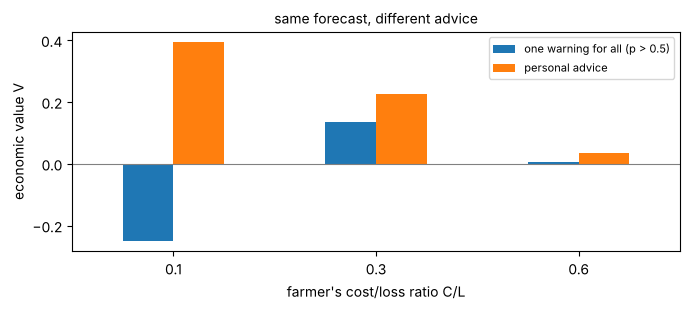

In [3]:
n_days = 4000
p = rng.beta(0.6, 3.4, n_days)                                     # reliable probabilities (as in session 10)
rain2 = rng.random(n_days) < p
s = rain2.mean()
LOSS = 20000.0                                                     # taka, assumed

def expense(act, cl):
    return np.mean(np.where(act, cl, rain2 * 1.0))                # per day, in units of the loss L

rows = []
for cl in [0.1, 0.3, 0.6]:
    e_clim, e_perf = min(cl, s), s * cl
    for name, act in [("personal advice", p > cl), ("one warning for all (p > 0.5)", p > 0.5)]:
        e = expense(act, cl)
        rows.append((cl, name, (e_clim - e) / (e_clim - e_perf), 30 * (e_clim - e) * LOSS))
    rows.append((cl, "no forecast", 0.0, 0.0))
table = pd.DataFrame(rows, columns=["farmer's C/L", "advice", "value V", "taka saved per 30 days"])
print(f"heavy rain on {s:.3f} of days")
print(table.to_string(index=False, float_format=lambda v: f"{v:,.2f}"))

piv = table[table["advice"] != "no forecast"].pivot(index="farmer's C/L", columns="advice", values="value V")
ax = piv.plot.bar(figsize=(7, 3.2), rot=0)
ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("economic value V"); ax.set_xlabel("farmer's cost/loss ratio C/L")
ax.set_title("same forecast, different advice", fontsize=10); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 4. A model card
A **model card** (Mitchell et al. 2019; Course 5 session 11) is a short document that travels with a model: what it is for and not for, what data it saw, how it was evaluated, how it fails and who could be harmed. Here is one for the small U-Net flood mapper of session 8, filled in with that notebook's results.

In [4]:
card = {
    "Model": "Small U-Net (2 levels, 13,033 weights) that labels each pixel of a radar (SAR) backscatter image as water or not; "
             "trained in Course 13 session 8, November 2026.",
    "Intended use": "Teaching: showing how a CNN maps flood water from radar and how to evaluate it.",
    "Not for": "Real flood response, relief targeting or compensation decisions; other sensors or polarizations; flooded "
               "vegetation or urban floods, which look different in radar.",
    "Training data": "200 synthetic 64 x 64 scenes with 4-look speckle: fields, a meandering river, flooded fields, sandbars, "
                     "buildings. No real images.",
    "Evaluation data": "50 synthetic test scenes of the same kind, and the same scenes made 3 dB darker (a calibration shift).",
    "Metrics": "Water IoU (main), pixel accuracy (reported only next to IoU, because water is 14.5% of pixels).",
    "Results": "IoU 0.971 on test scenes (Otsu baseline 0.890; fixed -15 dB threshold 0.947); 0.864 on scenes with under 5% "
               "water; 0.871 on the 3 dB darker scenes, below Otsu's unchanged 0.890.",
    "Known failures": "Sensitive to calibration: a 3 dB shift cost 0.100 IoU. Not tested on wind-roughened water, radar "
                      "shadow or real speckle statistics.",
    "Who could be harmed": "People whose flooded fields or homes are missed (delayed help); places wrongly shown as flooded "
                           "(misdirected resources).",
    "Recommendations": "Validate on hand-labelled real scenes from the region and season of use (for example Sen1Floods11 and "
                       "local labels); test darker and brighter calibrations; report IoU per scene with confidence intervals.",
}
print("# Model card: session 8 flood mapper\n")
for k, v in card.items():
    print(f"**{k}.** {v}\n")
print(f"runtime so far {time.time() - t_start:.0f} s")

# Model card: session 8 flood mapper

**Model.** Small U-Net (2 levels, 13,033 weights) that labels each pixel of a radar (SAR) backscatter image as water or not; trained in Course 13 session 8, November 2026.

**Intended use.** Teaching: showing how a CNN maps flood water from radar and how to evaluate it.

**Not for.** Real flood response, relief targeting or compensation decisions; other sensors or polarizations; flooded vegetation or urban floods, which look different in radar.

**Training data.** 200 synthetic 64 x 64 scenes with 4-look speckle: fields, a meandering river, flooded fields, sandbars, buildings. No real images.

**Evaluation data.** 50 synthetic test scenes of the same kind, and the same scenes made 3 dB darker (a calibration shift).

**Metrics.** Water IoU (main), pixel accuracy (reported only next to IoU, because water is 14.5% of pixels).

**Results.** IoU 0.971 on test scenes (Otsu baseline 0.890; fixed -15 dB threshold 0.947); 0.864 on scenes with under 5% water

### 5. Measuring emissions (NOT RUN here)
The `codecarbon` library measures a job's energy from the hardware's power readings where it can, and looks up a carbon intensity for your location. Its estimates have their own uncertainty, so report them as estimates with the method named.

In [ ]:
# NOT RUN: needs the codecarbon library (pip install codecarbon); it reads power counters, which need permissions on some machines
from codecarbon import EmissionsTracker

tracker = EmissionsTracker(project_name="course15_session12")
tracker.start()
HistGradientBoostingRegressor(max_iter=200, random_state=0).fit(X, y)
kg = tracker.stop()                                        # kg CO2-equivalent for the tracked code
print(f"estimated emissions: {kg * 1000:.3f} g CO2-eq")

### 6. Exercises

In [5]:
# TODO: your own numbers. Replace ASSUMED and GRIDS with figures for the hardware you used this term and a sourced
# carbon intensity for your grid (write the source in a comment). Recompute the table for your capstone's training and for
# one year of using it. Which costs more, and what would you change?
def my_footprint():
    return None          # replace with your code; return a DataFrame like `jobs`

r = my_footprint()
print("not done yet" if r is None else r)

not done yet


In [6]:
# TODO: your capstone plan as a model card. Fill in the same keys as `card` for the model you plan to build, plus three
# more: "Partner and decision" (who will use it and for what), "Validation split" (which districts or years are held out,
# and why) and "Baseline" (the simple method you must beat). Print it.
def capstone_card():
    return None          # replace with your dictionary

r = capstone_card()
print("not done yet" if r is None else "\n".join(f"**{k}.** {v}" for k, v in r.items()))

not done yet


### What to notice
(Written from the run above; the measured CPU time will differ on your machine, the other numbers will match if you keep the seeds.)

1. **Training dominates, and the grid matters as much as the hardware.** Under the stated assumptions, training a GraphCast-size model (32 devices for 4 weeks) used about 4,731 kWh: 237 kg CO₂ on a 0.05 kg/kWh grid, 2,839 kg at an assumed 0.6 and 4,258 kg at 0.9. A year of daily 10-day forecasts with it used 1.338 kWh, 3,535 times less. Fine-tuning a small CNN for 3 hours on one GPU used 0.99 kWh (0.594 kg at 0.6). The gradient-boosting model took well under a second of CPU time (the printed time varies from run to run), about a millionth of a kWh. These are orders of magnitude from assumed power, PUE and grid intensity, not measurements; section 5 shows how to measure.
2. **Honest advice quotes the record, not only the model's number.** This forecaster's 30–40% forecasts averaged 35%, but heavy rain followed 39% of them; its 70–80% forecasts averaged 74%, and rain followed 84%, but only 19 such forecasts exist, so that frequency is itself uncertain. The messages give the record ("about 4 times in 10", "about 8 times in 10") and how many past forecasts it rests on.
3. **One warning for everybody hurts some farmers.** With the same reliable forecast, personal advice gave $V$ = 0.39, 0.22 and 0.03 to farmers with $C/L$ = 0.1, 0.3 and 0.6 (20,265, 13,560 and 1,200 taka saved per 30 days, for an assumed loss of 20,000 taka). A single warning at $p > 0.5$ gave 0.14 and 0.01 to the last two, and −0.25 to the first: that farmer lost 12,870 taka compared with simply protecting every day, because cheap protection pays at probabilities far below 0.5.
4. **A model card records what one accuracy number hides.** The flood mapper's card puts its 0.971 IoU next to the 0.100 it lost under a 3 dB calibration shift (0.871, below Otsu's 0.890), says it never saw a real image, and names who could be harmed by its errors.